# ЛР № 01. Основы языковых моделей

**Профиль:** Greenfield Town  
**Seed:** 42

In [1]:
from __future__ import annotations
from collections import Counter, defaultdict
import json, math, random, re
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True

possible = [Path.cwd(), Path.cwd() / "data", Path.cwd().parent / "data"]
SCENARIO_PATH = next((p / "greenfield_town.json" for p in possible if (p / "greenfield_town.json").is_file()), None)
if SCENARIO_PATH is None:
    raise FileNotFoundError("Не найден data/greenfield_town.json рядом с ноутбуком.")
SCENARIO = json.loads(SCENARIO_PATH.read_text(encoding="utf-8"))
print(f"Профиль: {SCENARIO['title']}")

Профиль: Greenfield Town


## 1. Мешок слов и n-граммы

In [2]:
def tokenize(text: str) -> list[str]:
    return re.findall(r"[a-z]+", text.lower())

def build_vocabulary(texts: list[str]) -> dict[str, int]:
    tokens = set()
    for text in texts:
        tokens.update(tokenize(text))
    return {token: i for i, token in enumerate(sorted(tokens))}

def doc_to_bow(text: str, vocabulary: dict[str, int]) -> list[int]:
    vector = [0] * len(vocabulary)
    for token in set(tokenize(text)):
        if token in vocabulary:
            vector[vocabulary[token]] = 1
    return vector

def make_ngrams(tokens: list[str], n: int) -> list[tuple[str, ...]]:
    if n < 1:
        raise ValueError("n >= 1")
    return [tuple(tokens[i:i+n]) for i in range(len(tokens) - n + 1)]

In [3]:
classification_data = SCENARIO["classification"]
CLASS_NAMES = classification_data["class_names"]
DOCS = [r["text"] for r in classification_data["documents"]]
class_to_id = {c: i for i, c in enumerate(CLASS_NAMES)}
LABELS = torch.tensor([class_to_id[r["label"]] for r in classification_data["documents"]], dtype=torch.long)
vocabulary = build_vocabulary(DOCS)
document_vectors = torch.tensor([doc_to_bow(d, vocabulary) for d in DOCS], dtype=torch.float32)
print(f"Словарь: {len(vocabulary)}")
print(f"DTM: {tuple(document_vectors.shape)}; плотность: {float(document_vectors.mean()):.3f}")
first_text, second_text = classification_data["order_examples"]
order_vocab = build_vocabulary([first_text, second_text])
print("BoW совпадают:", doc_to_bow(first_text, order_vocab) == doc_to_bow(second_text, order_vocab))
print("Биграммы 1:", make_ngrams(tokenize(first_text), 2))
print("Биграммы 2:", make_ngrams(tokenize(second_text), 2))

Словарь: 38
DTM: (12, 38); плотность: 0.151
BoW совпадают: True
Биграммы 1: [('garden', 'gate'), ('gate', 'opens')]
Биграммы 2: [('opens', 'gate'), ('gate', 'garden')]


**Вывод 1.** DTM разрежена, так как документ содержит малую часть словаря. BoW теряет порядок слов. Биграммы возвращают локальный порядок, но увеличивают размерность признаков.

## 2. Softmax и классификатор

In [4]:
class SimpleClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dim: int, output_dim: int):
        super().__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(self.relu(self.fc1(x)))

In [5]:
logits_example = torch.tensor([2.0, 1.0, 0.5])
probs_example = torch.softmax(logits_example, dim=0)
manual_loss = -math.log(float(probs_example[0]))
torch_loss = nn.CrossEntropyLoss()(logits_example.unsqueeze(0), torch.tensor([0]))
print("Softmax:", probs_example.numpy().round(4))
print(f"Сумма: {probs_example.sum():.6f}")
print(f"Loss вручную: {manual_loss:.6f}; PyTorch: {torch_loss.item():.6f}")
assert torch.isclose(probs_example.sum(), torch.tensor(1.0))
assert math.isclose(manual_loss, torch_loss.item(), rel_tol=1e-6)

Softmax: [0.6285 0.2312 0.1402]
Сумма: 1.000000
Loss вручную: 0.464369; PyTorch: 0.464369


In [6]:
torch.manual_seed(SEED)
classifier_model = SimpleClassifier(len(vocabulary), 24, len(CLASS_NAMES))
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(classifier_model.parameters(), lr=0.05)
losses = []
classifier_model.train()
for _ in range(800):
    optimizer.zero_grad()
    logits = classifier_model(document_vectors)
    loss = criterion(logits, LABELS)
    loss.backward()
    optimizer.step()
    losses.append(float(loss.detach()))

classifier_model.eval()
NEW_DOCS = classification_data["new_documents"]
new_vectors = torch.tensor([doc_to_bow(d, vocabulary) for d in NEW_DOCS], dtype=torch.float32)
with torch.no_grad():
    new_logits = classifier_model(new_vectors)
    pred_ids = torch.argmax(new_logits, dim=1)
print(f"Loss: {losses[0]:.4f} -> {losses[-1]:.4f}")
print("Форма логитов:", tuple(new_logits.shape))
assert tuple(new_logits.shape) == (len(NEW_DOCS), len(CLASS_NAMES))
for d, cid in zip(NEW_DOCS, pred_ids.tolist()):
    print(f"{d} -> {CLASS_NAMES[cid]}")

Loss: 1.1270 -> 0.0066
Форма логитов: (2, 3)
fresh bread and cakes -> Bakery
readers visit the quiet library -> Library


**Вывод 2.** Softmax в forward не нужен, так как CrossEntropyLoss ожидает сырые логиты и сам выполняет устойчивый softmax+log. argmax(dim=1) выбирает лучший класс для каждого документа.

## 3. Skip-gram и эмбеддинги

In [7]:
def make_skipgram_pairs(tokens: list[str], window_size: int) -> list[tuple[str, str]]:
    pairs = []
    for i, center in enumerate(tokens):
        left = max(0, i - window_size)
        right = min(len(tokens), i + window_size + 1)
        for j in range(left, right):
            if j != i:
                pairs.append((center, tokens[j]))
    return pairs

class SkipGramModel(nn.Module):
    def __init__(self, vocab_size: int, embedding_dim: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center_ids: torch.Tensor) -> torch.Tensor:
        return self.output(self.embedding(center_ids))

def nearest_words(word: str, vocabulary: dict[str, int], vectors: torch.Tensor, top_k: int = 3):
    if word not in vocabulary:
        return []
    idx = vocabulary[word]
    normalized = F.normalize(vectors, p=2, dim=1)
    scores = torch.matmul(normalized, normalized[idx])
    scores[idx] = -1.0
    top_ids = torch.topk(scores, top_k).indices
    inverse = {i: w for w, i in vocabulary.items()}
    return [(inverse[i.item()], float(scores[i])) for i in top_ids]

Пар: 216, словарь: 28
Ближайшие к 'gardener': [('oven', 0.624), ('book', 0.621), ('waters', 0.568)]
Ближайшие к 'baker': [('sells', 0.587), ('book', 0.512), ('gardener', 0.503)]


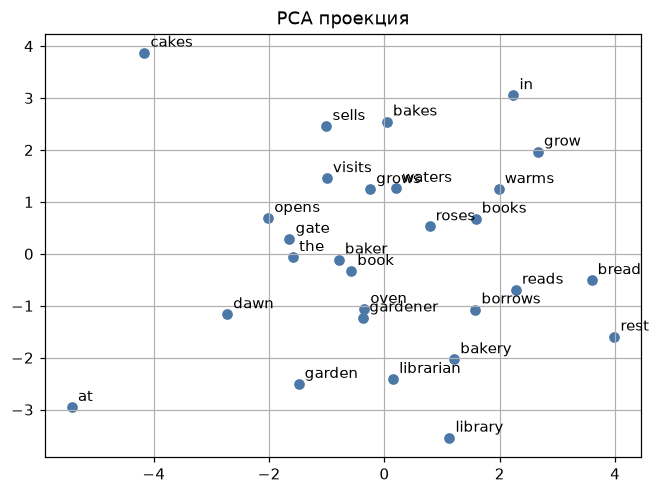

In [8]:
emb_data = SCENARIO["embedding"]
lines = emb_data["lines"]
emb_vocab = build_vocabulary(lines)
pairs = [p for line in lines for p in make_skipgram_pairs(tokenize(line), emb_data["window_size"])]
center_ids = torch.tensor([emb_vocab[c] for c, _ in pairs], dtype=torch.long)
context_ids = torch.tensor([emb_vocab[ctx] for _, ctx in pairs], dtype=torch.long)
print(f"Пар: {len(pairs)}, словарь: {len(emb_vocab)}")
assert all(c != ctx for c, ctx in pairs)

torch.manual_seed(SEED)
skipgram = SkipGramModel(len(emb_vocab), emb_data["embedding_dim"])
sg_opt = torch.optim.Adam(skipgram.parameters(), lr=emb_data["learning_rate"])
skipgram.train()
for _ in range(emb_data["steps"]):
    sg_opt.zero_grad()
    loss = nn.CrossEntropyLoss()(skipgram(center_ids), context_ids)
    loss.backward()
    sg_opt.step()

skipgram.eval()
embeddings = skipgram.embedding.weight.detach()
for q in emb_data["query_words"]:
    print(f"Ближайшие к {q!r}:", [(w, round(s, 3)) for w, s in nearest_words(q, emb_vocab, embeddings)])

matrix = embeddings.numpy()
centered = matrix - matrix.mean(axis=0, keepdims=True)
_, _, vt = np.linalg.svd(centered, full_matrices=False)
coords = centered @ vt[:2].T
inv_emb = {i: w for w, i in emb_vocab.items()}
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(coords[:, 0], coords[:, 1], color="#4c78a8")
for i, p in enumerate(coords):
    ax.annotate(inv_emb[i], p, xytext=(4, 4), textcoords="offset points")
ax.set_title("PCA проекция")
plt.show()

**Вывод 3.** Слова gardener, baker, librarian встречаются в похожих контекстах, поэтому их векторы близки. На малом корпусе это наблюдение, а не доказательство семантики.

## 4. BPE

In [9]:
def initialize_vocabulary(corpus: list[str]):
    vocabulary = defaultdict(int)
    charset = set()
    for word in corpus:
        characters = list("_" + word)
        vocabulary[" ".join(characters)] += 1
        charset.update(characters)
    return dict(vocabulary), charset

def get_pair_counts(vocabulary: dict[str, int]):
    pair_counts = defaultdict(int)
    for word, word_count in vocabulary.items():
        tokens = word.split()
        for i in range(len(tokens) - 1):
            pair_counts[(tokens[i], tokens[i + 1])] += word_count
    return dict(pair_counts)

def merge_pair(vocabulary: dict[str, int], pair: tuple[str, str]):
    left, right = re.escape(pair[0]), re.escape(pair[1])
    pattern = re.compile(r"(?<!\S)" + left + r" " + right + r"(?!\S)")
    return {pattern.sub("".join(pair), word): count for word, count in vocabulary.items()}

def byte_pair_encoding(corpus: list[str], vocab_size: int):
    vocabulary, charset = initialize_vocabulary(corpus)
    tokens = set(charset)
    merges: list[tuple[str, str]] = []
    while len(tokens) < vocab_size:
        pair_counts = get_pair_counts(vocabulary)
        if not pair_counts:
            break
        pair = max(pair_counts, key=pair_counts.get)
        merged = "".join(pair)
        if merged in tokens:
            break
        vocabulary = merge_pair(vocabulary, pair)
        merges.append(pair)
        tokens.add(merged)
    return vocabulary, merges, charset, tokens

def tokenize_word(word: str, merges: list[tuple[str, str]], charset: set[str], unk_token: str = "<UNK>"):
    word_tokens = [c if c in charset else unk_token for c in "_" + word.lower()]
    for left, right in merges:
        i = 0
        while i < len(word_tokens) - 1:
            if word_tokens[i:i + 2] == [left, right]:
                word_tokens[i:i + 2] = [left + right]
            else:
                i += 1
    return word_tokens

In [10]:
bpe_data = SCENARIO["bpe"]
bpe_corpus = [t for text in bpe_data["corpus"] for t in tokenize(text)]
bpe_vocab, merges, charset, bpe_tokens = byte_pair_encoding(bpe_corpus, bpe_data["vocab_size"])
print(f"Алфавит: {len(charset)}; BPE-словарь: {len(bpe_tokens)}; слияний: {len(merges)}")
for w in bpe_data["probe_words"]:
    print(f"{w:12s} -> {tokenize_word(w, merges, charset)}")
assert len(bpe_tokens) <= bpe_data["vocab_size"]
assert "<UNK>" in tokenize_word(bpe_data["probe_words"][-1], merges, charset)

Алфавит: 17; BPE-словарь: 50; слияний: 33
garden       -> ['_garden']
garden7      -> ['_garden', '<UNK>']


**Вывод 4.** Частота пары учитывает частоту целого слова. <UNK> — неизвестный символ BPE. Порядок merges важен: каждое слияние меняет будущие пары.

## 5. Счётная триграммная LM

In [11]:
class CountLanguageModel:
    def __init__(self, n: int):
        if n < 1:
            raise ValueError("n >= 1")
        self.n = n
        self.ngram_counts = [defaultdict(Counter) for _ in range(n)]
        self.total_unigrams = 0
        self.vocabulary = {"<unk>"}

    def predict_next_token(self, context):
        for order in range(self.n, 1, -1):
            if len(context) >= order - 1:
                key = tuple(context[-(order - 1):])
                counts = self.ngram_counts[order - 1].get(key)
                if counts:
                    return counts.most_common(1)[0][0]
        uni = self.ngram_counts[0].get((), Counter())
        return uni.most_common(1)[0][0] if uni else None

    def get_probability(self, token: str, context) -> float:
        token = token if token in self.vocabulary else "<unk>"
        V = len(self.vocabulary)
        for order in range(self.n, 1, -1):
            if len(context) >= order - 1:
                key = tuple(context[-(order - 1):])
                counts = self.ngram_counts[order - 1].get(key)
                if counts:
                    return (counts[token] + 1) / (sum(counts.values()) + V)
        uni = self.ngram_counts[0].get((), Counter())
        return (uni[token] + 1) / (self.total_unigrams + V)

def train(model: CountLanguageModel, tokens: list[str]):
    model.total_unigrams = len(tokens)
    model.vocabulary = set(tokens) | {"<unk>"}
    for order in range(1, model.n + 1):
        counts = model.ngram_counts[order - 1]
        for i in range(len(tokens) - order + 1):
            ctx = tuple(tokens[i:i + order - 1])
            nxt = tokens[i + order - 1]
            counts[ctx][nxt] += 1

def generate_text(model, context: list[str], num_tokens: int) -> str:
    out = list(context)
    for _ in range(num_tokens):
        nxt = model.predict_next_token(out)
        if nxt is None:
            break
        out.append(nxt)
    return " ".join(out)

def compute_perplexity(model, tokens: list[str], context_size: int) -> float:
    if not tokens:
        return float("inf")
    total = 0.0
    for i, t in enumerate(tokens):
        ctx = tokens[max(0, i - context_size):i]
        total += math.log(model.get_probability(t, ctx))
    return math.exp(-total / len(tokens))

In [12]:
lm_data = SCENARIO["language_model"]
train_tokens = tokenize(lm_data["train_text"])
test_tokens = tokenize(lm_data["test_text"])
lm = CountLanguageModel(lm_data["n"])
train(lm, train_tokens)
known = lm_data["known_context"]
unknown = lm_data["unknown_context"]
print("Знакомый:", known, "->", lm.predict_next_token(known))
print("Незнакомый:", unknown, "->", lm.predict_next_token(unknown))
print("P(unknown|unknown ctx):", f"{lm.get_probability('unknown', unknown):.8f}")
p_sum = sum(lm.get_probability(t, known) for t in lm.vocabulary)
print(f"Сумма вероятностей: {p_sum:.12f}")
print("Генерация:", generate_text(lm, lm_data["generation_context"], lm_data["generation_length"]))
assert lm.get_probability("unknown", unknown) > 0
assert math.isclose(p_sum, 1.0, rel_tol=1e-12, abs_tol=1e-12)

Знакомый: ['the', 'garden'] -> gate
Незнакомый: ['silent', 'garden'] -> gate
P(unknown|unknown ctx): 0.05555556
Сумма вероятностей: 1.000000000000
Генерация: the garden gate opens at dawn the


**Вывод 5.** Backoff идёт от триграммы к биграмме и униграмме. Сглаживание Лапласа нужно, чтобы избежать log(0) при расчёте PPL. Триграмма видит только 2 предыдущих слова.

## 6. Перплексия, ROUGE и Elo

In [13]:
perplexity = compute_perplexity(lm, test_tokens, context_size=lm.n - 1)
print(f"Перплексия: {perplexity:.2f}")
assert math.isfinite(perplexity)

Перплексия: 5.63


In [14]:
def ngram_counter(text: str, n: int) -> Counter:
    return Counter(make_ngrams(tokenize(text), n))

def rouge_n_recall(generated: str, reference: str, n: int) -> float:
    ref = ngram_counter(reference, n)
    gen = ngram_counter(generated, n)
    total = sum(ref.values())
    if total == 0:
        return 0.0
    overlap = sum(min(c, gen[g]) for g, c in ref.items())
    return overlap / total

def lcs_length(left: list[str], right: list[str]) -> int:
    table = [[0] * (len(right) + 1) for _ in range(len(left) + 1)]
    for i in range(1, len(left) + 1):
        for j in range(1, len(right) + 1):
            if left[i-1] == right[j-1]:
                table[i][j] = table[i-1][j-1] + 1
            else:
                table[i][j] = max(table[i-1][j], table[i][j-1])
    return table[-1][-1]

def rouge_l(generated: str, reference: str, beta: float = 8.0) -> float:
    gen_tokens, ref_tokens = tokenize(generated), tokenize(reference)
    if not gen_tokens or not ref_tokens:
        return 0.0
    lcs = lcs_length(gen_tokens, ref_tokens)
    recall = lcs / len(ref_tokens)
    precision = lcs / len(gen_tokens)
    if recall + beta ** 2 * precision == 0:
        return 0.0
    return (1 + beta ** 2) * recall * precision / (recall + beta ** 2 * precision)

def expected_score(rating_a: float, rating_b: float) -> float:
    return 1 / (1 + 10 ** ((rating_b - rating_a) / 400))

def update_elo(rating: float, actual_score: float, expected: float, k: float = 32) -> float:
    return rating + k * (actual_score - expected)

In [15]:
evaluation_data = SCENARIO["evaluation"]
reference = evaluation_data["reference"]
candidate_by_name = {item["name"]: item["text"] for item in evaluation_data["candidates"]}

rows = []
for name, candidate in candidate_by_name.items():
    rows.append((name, rouge_n_recall(candidate, reference, 1), rouge_n_recall(candidate, reference, 2), rouge_l(candidate, reference)))
print("Модель | ROUGE-1 | ROUGE-2 | ROUGE-L")
for name, r1, r2, rl in rows:
    print(f"{name:6s} | {r1:7.3f} | {r2:7.3f} | {rl:7.3f}")
assert all(0 <= v <= 1 for _, *values in rows for v in values)

matches = [(l, r, float(s)) for l, r, s in evaluation_data["elo_matches"]]
ratings = {name: 1500.0 for name in evaluation_data["elo_names"]}
for left, right, left_score in matches:
    exp_left = expected_score(ratings[left], ratings[right])
    exp_right = 1 - exp_left
    ratings[left] = update_elo(ratings[left], left_score, exp_left)
    ratings[right] = update_elo(ratings[right], 1 - left_score, exp_right)
print("Итоговые Elo:")
for n, r in sorted(ratings.items(), key=lambda x: x[1], reverse=True):
    print(f"{n}: {r:.1f}")
assert math.isclose(sum(ratings.values()), 4500.0, rel_tol=1e-12)

Модель | ROUGE-1 | ROUGE-2 | ROUGE-L
A      |   1.000 |   0.600 |   0.831
B      |   0.000 |   0.000 |   0.000
Итоговые Elo:
Bakery-LM: 1501.5
Garden-LM: 1499.3
Library-LM: 1499.2


**Вывод 6.** ROUGE измеряет лексическое перекрытие и не проверяет истинность. PPL не заменяет оценку смысла. Elo требует многих сравнений. Лайкерт кандидата A: связность=1, информативность=0, факт. точность=0.